# 02 Expected yield and KPIs — PVDAQ system 9069 (Simon Solar Farm, GA)

Goal of Phase 2: a transparent expected-yield model and the plant KPIs (performance ratio, specific
yield, availability) on the clean dataset of Phase 1 (`data/processed/9069`, 2020-05 … 2023-11).

Methodological decisions (options and trade-offs discussed before coding):
- **PR** after IEC 61724-1, ratio of sums over one mask, at inverter-step level. Three temperature
  treatments are computed side by side and compared: **A** raw, **B** T_ref = 25 °C,
  **C** T_ref = POA-weighted mean cell temperature of the period (NREL weather-corrected PR).
  Each with and without downtime; a second PR at the plant meter.
- **Cell temperature** = measured back-of-module (thermocouples 01 / 06 s1 / 10) + 3 °C × G/1000.
- **Model**: pvlib PVWatts DC (nameplate, gamma) × explicit design losses → PVWatts inverter clipped
  at 825 kW, per inverter block. **Not calibrated** on the data: the gap to the measurements is the
  subject of the loss analysis.
- **Availability**: time-based, inverter is down if AC < 1 % of rating while POA > 50 W/m².

Sections:
1. Inputs and plausibility
2. Time offset between AC power and irradiance
3. Temperature coefficient gamma measured on the plant
4. Drift of reference cells against pyranometer 02B
5. Expected-yield model
6. PR: A vs B vs C
7. KPIs: specific yield, availability, downtime map
8. Conclusions

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

# Run from the project root so that `src` imports and relative paths in the config work.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd

from src import kpi, model, plots
from src import sensor_checks as sc
from src.config import load_config

pd.set_option("display.width", 160)
config = load_config("configs/system_9069.yaml")
FIG = Path("reports/figures")

## 1. Inputs and plausibility

Model inputs from the clean dataset, flagged values (stale / out of range) set to NaN:
POA = mean of the valid reference cells 04 / 10, module temperature = mean of the valid
thermocouples, AC of 40 inverters (NaN = unknown, 0 = measured zero), plant meter 2.
Plausibility is checked with physical limits, not only coverage (lesson of thermocouple 03).

In [2]:
inputs, ac = model.load_inputs(config)
t_cell = model.cell_temperature(inputs, config)
day = inputs["daylight"]
print(f"steps: {len(inputs):,}  daylight: {day.sum():,}  inverters: {ac.shape[1]}")
desc = inputs.assign(t_cell_c=t_cell)[day].drop(columns=["daylight"]).describe().T
desc.round(1)

steps: 376,654  daylight: 192,042  inverters: 40


,count,mean,std,min,25%,50%,75%,max
poa_wm2,187874.0,399.9,322.9,1.0,96.5,328.0,684.4,1260.0
t_mod_c,187803.0,31.2,13.7,-14.7,21.4,30.4,41.9,66.7
t_amb_c,176832.0,24.5,9.0,-12.2,18.6,25.7,31.4,43.9
p_ac_meter_kw,191997.0,10111.0,8647.0,0.0,2112.2,8028.4,17293.3,32178.7
sun_elevation_deg,192042.0,34.1,20.7,0.0,17.2,32.7,49.2,79.8
poa_clearsky_wm2,192042.0,539.2,324.8,0.0,242.4,596.5,830.7,1015.7
t_cell_c,187537.0,32.4,14.5,-14.7,21.8,31.4,43.8,70.3


In [3]:
# Physical limits of the derived series (raw limits were flagged in Phase 1).
checks = {
    "POA > 1500 W/m2": (inputs["poa_wm2"] > 1500).sum(),
    "T_cell > 85 C": (t_cell > 85).sum(),
    "T_cell below T_amb - 10 C at POA > 300": ((t_cell - inputs["t_amb_c"] < -10) & (inputs["poa_wm2"] > 300)).sum(),
    "inverter AC > 105 % of 825 kW": (ac > 1.05 * 825).sum().sum(),
    "share of daylight steps with T_cell": t_cell[day].notna().mean().round(4),
    "share of daylight steps with POA": inputs["poa_wm2"][day].notna().mean().round(4),
}
pd.Series(checks)

POA > 1500 W/m2                           0.0000
T_cell > 85 C                             0.0000
T_cell below T_amb - 10 C at POA > 300    0.0000
inverter AC > 105 % of 825 kW             0.0000
share of daylight steps with T_cell       0.9765
share of daylight steps with POA          0.9783
dtype: float64

## 2. Time offset between AC power and irradiance

Open question from Phase 1: on clear days AC power seems 5–10 min *earlier* than irradiance.
Is it a clock / interval-label problem, or the shape of the AC curve?

Test: correlation of AC (median over running inverters) with POA for shifts of ±20 min on clear
days (days whose POA follows the clear-sky curve, r ≥ 0.998; works without GHI, which ends
2022-03). The best shift is refined between 5-min steps with a parabola (precision about ±2.5 min).
A clock error shifts morning and afternoon equally; a curve-shape effect does not.
The sun is the reference: measured POA is compared with the clear-sky POA model first.

In [4]:
sun = sc.sun_and_aoi(inputs.index, config)
clear = sc.clear_days_from_poa(inputs["poa_wm2"], inputs["poa_clearsky_wm2"], day)
print("clear days:", len(clear))

ac_median = ac.where(ac > 0).median(axis=1)       # typical running inverter
gamma = model.weighted_gamma(config)
# AC divided by the temperature factor: removes the effect of the modules heating up over the day.
ac_tcorr = ac_median / (1 + gamma * (t_cell - 25))
lit = (inputs["poa_wm2"] > 50) & day
unclipped = ac_median < 700                        # clipping flattens the curve near noon
morning = sun["sun_azimuth_deg"] < 180             # split at solar noon, not at 12:00 clock time

lags = range(-4, 5)   # steps of 5 min; positive = second series shifted later
rows = {
    "POA vs clear-sky POA model": (inputs["poa_wm2"], inputs["poa_clearsky_wm2"], lit),
    "AC vs POA, all": (ac_median, inputs["poa_wm2"], lit & unclipped),
    "AC vs POA, morning": (ac_median, inputs["poa_wm2"], lit & unclipped & morning),
    "AC vs POA, afternoon": (ac_median, inputs["poa_wm2"], lit & unclipped & ~morning),
    "T-corrected AC vs POA, all": (ac_tcorr, inputs["poa_wm2"], lit & unclipped),
    "T-corrected AC vs POA, morning": (ac_tcorr, inputs["poa_wm2"], lit & unclipped & morning),
    "T-corrected AC vs POA, afternoon": (ac_tcorr, inputs["poa_wm2"], lit & unclipped & ~morning),
}
lag_table = pd.Series({name: sc.peak_lag_minutes(sc.lag_curve(a, b, clear, lags, mask))
                       for name, (a, b, mask) in rows.items()}, name="best shift of 2nd series, min")
# A negative shift of POA means AC leads POA.
lag_table.round(1)

clear days: 104


POA vs clear-sky POA model           2.0
AC vs POA, all                      -7.3
AC vs POA, morning                 -14.3
AC vs POA, afternoon                 0.1
T-corrected AC vs POA, all          -4.7
T-corrected AC vs POA, morning       0.4
T-corrected AC vs POA, afternoon    -1.9
Name: best shift of 2nd series, min, dtype: float64

## 3. Temperature coefficient gamma measured on the plant

Datasheet values: −0.28 %/°C (295 W modules, 20 % of DC) and −0.45 %/°C (300 W, 80 %);
DC-weighted mean −0.416 %/°C. Is −0.28 real? If the 295 W modules sat on their own inverters
(25 992 modules ≈ 8 inverter blocks of ≈ 3 235 modules), those inverters would show a flatter slope.

Fit per inverter: normalised power y = P_AC / (P0 × G/1000) = a + b (G − 800) + c (T_cell − 25),
gamma = c / a. Steps: POA 700–900 W/m², AOI < 40°, AC < 95 % of rating (no clipping),
y > 0.5 (inverter running). The **within-month** fit centres the data on each month first, so
seasonal spectrum, soiling and degradation do not leak into the temperature slope.
The slope is measured on AC, so it also contains the (small) temperature dependence of the
inverter efficiency and cable losses.

In [5]:
p0_inv = model.inverter_dc_kw(config)
gamma_table = sc.gamma_per_inverter(inputs, ac, t_cell, sun["aoi_deg"], config, p0_inv).astype(float)
print(f"nameplate DC-weighted gamma: {100 * gamma:.3f} %/C")
gamma_table[["pooled", "within_month", "y_mean"]].describe().round(3)

nameplate DC-weighted gamma: -0.416 %/C


,pooled,within_month,y_mean
count,40.000,40.000,40.000
mean,-0.347,-0.335,0.783
std,0.032,0.040,0.014
min,-0.440,-0.380,0.756
25%,-0.363,-0.367,0.772
50%,-0.351,-0.354,0.783
75%,-0.330,-0.309,0.792
max,-0.266,-0.235,0.810


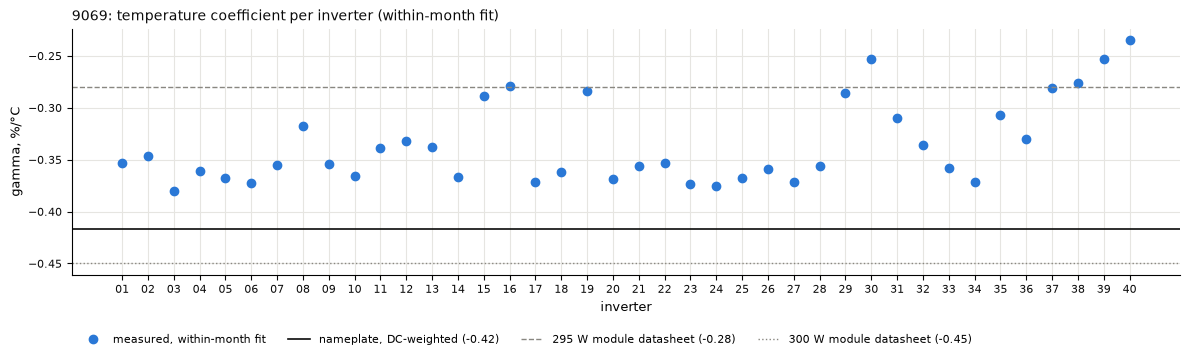

In [6]:
fig = plots.gamma_plot(gamma_table, 100 * gamma,
                       title="9069: temperature coefficient per inverter (within-month fit)")
fig.savefig(FIG / "9069_gamma_per_inverter.png", dpi=130)

In [7]:
g = gamma_table["within_month"]
groups = pd.Series(np.where(g.index.str[8:10].astype(int) <= 28, "inverters 01-28", "inverters 29-40"), index=g.index)
g.groupby(groups).agg(["mean", "std", "count"]).round(3)

,mean,std,count
inverters 01-28,-0.351,0.027,28
inverters 29-40,-0.300,0.043,12


## 4. Drift of reference cells against pyranometer 02B

After 2022-05 there is no class-A pyranometer, so PR rests on reference cells 04 / 10. Do the
cells drift against pyranometer 02B in 2020-07 … 2022-04?

Method: ratio cell / 02B per 5-min step (POA > 500 W/m², AOI < 50°), daily median over ≥ 40
steps, monthly median, then **year-over-year**: each month against the same month a year earlier,
so the seasonal difference of spectral and angular response between a silicon cell and a
thermopile cancels. Cloudy days are allowed: both sensors see the same sky. Without the
pyranometer only cell 04 vs cell 10 can be followed; a common drift of both is then invisible.

In [8]:
sensors = sc.load_irradiance_sensors(config, ["poa_ref01_wm2", "poa_ref04_wm2", "poa_ref10_wm2", "poa_pyr02b_wm2"])
mask = (inputs["poa_wm2"] > 500) & (sun["aoi_deg"] < 50) & day
pyr = sensors["poa_pyr02b_wm2"]
daily = pd.DataFrame({
    "cell 04 / 02B": sc.daily_ratio(sensors["poa_ref04_wm2"], pyr, mask),
    "cell 10 / 02B": sc.daily_ratio(sensors["poa_ref10_wm2"], pyr, mask),
    "cell 01 / 02B": sc.daily_ratio(sensors["poa_ref01_wm2"], pyr, mask),
    "cell 04 / cell 10": sc.daily_ratio(sensors["poa_ref04_wm2"], sensors["poa_ref10_wm2"], mask),
})
window = daily.loc["2020-07-01":"2022-04-30"]
rows = {c: sc.yoy_drift(window[c]) for c in daily.columns[:3]}
rows["cell 04 / cell 10, whole period"] = sc.yoy_drift(daily["cell 04 / cell 10"])
rows["cell 04 / cell 10, 2021-05 … 2023-11"] = sc.yoy_drift(daily.loc["2021-05-01":, "cell 04 / cell 10"])
drift = pd.DataFrame(rows, index=["median %/yr", "min", "max", "pairs"]).T
drift.round(2)

,median %/yr,min,max,pairs
cell 04 / 02B,-0.63,-1.45,1.13,10.0
cell 10 / 02B,-1.00,-2.27,0.28,10.0
cell 01 / 02B,-0.16,-1.39,0.78,10.0
"cell 04 / cell 10, whole period",-0.12,-4.30,4.22,31.0
"cell 04 / cell 10, 2021-05 … 2023-11",-0.67,-4.30,1.20,19.0


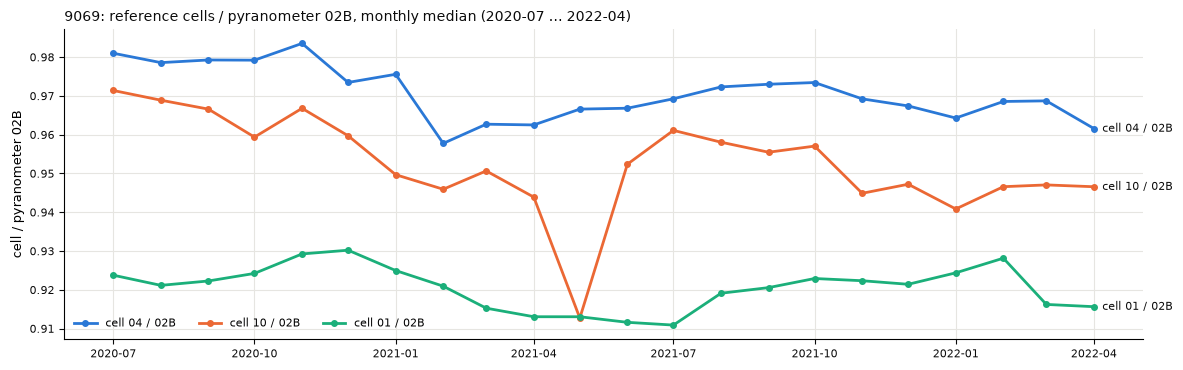

In [9]:
monthly_ratio = window[daily.columns[:3]].groupby(window.index.to_period("M")).median()
fig = plots.drift_plot(monthly_ratio, title="9069: reference cells / pyranometer 02B, monthly median (2020-07 … 2022-04)")
fig.savefig(FIG / "9069_cell_drift.png", dpi=130)

## 5. Expected-yield model

One inverter block = 38 687 / 40 = 967 kW DC (equal blocks: running inverters have the same
normalised power, `y_mean` in section 3). Chain: `pvwatts_dc` (nameplate, gamma −0.416 %/°C,
T_cell) → × (1 − design DC losses) → `pvlib.inverter.pvwatts` (η_nom 0.98), clipped at 825 kW.
Design losses come from `configs/system_9069.yaml` (`model.dc_losses_pct`); soiling, shading,
availability and degradation are deliberately 0: they are what the audit measures.

In [10]:
print(f"DC design losses: {100 * model.dc_loss_fraction(config):.2f} %   "
      f"inverter DC: {p0_inv:.1f} kW   gamma: {100 * gamma:.3f} %/C")
expected = model.expected_power(inputs["poa_wm2"], t_cell, config)
expected[day].describe().round(1)

DC design losses: 6.34 %   inverter DC: 967.2 kW   gamma: -0.416 %/C


,p_dc_kw,p_ac_kw
count,187537.0,187537.0
mean,338.0,330.0
std,262.4,258.5
min,1.0,0.0
25%,89.3,84.3
50%,289.3,283.3
75%,573.8,563.7
max,1051.9,825.0


In [11]:
# Measured / expected for running inverters (AC > 0.5 x expected), unclipped, mid irradiance:
# the gap the loss analysis must explain, before any outage.
mid = day & inputs["poa_wm2"].between(400, 900) & (expected["p_ac_kw"] < 0.95 * 825)
ratio = ac[mid].div(expected["p_ac_kw"][mid], axis=0)
ratio = ratio.where(ratio > 0.5)
by_year = ratio.groupby(ratio.index.tz_convert("America/New_York").year).median().median(axis=1)
print("median measured / expected of running inverters, by local year:")
by_year.round(3)

median measured / expected of running inverters, by local year:


time_utc
2020    0.935
2021    0.918
2022    0.919
2023    0.886
dtype: float64

## 6. PR: A vs B vs C

T_ref of variant C is computed once for the whole period (POA-weighted mean cell temperature) and
fixed, so the years stay comparable. The comparison uses PR excluding downtime: outages would
otherwise dominate the curves and hide the temperature effect.

In [12]:
t_ref = kpi.weighted_t_ref(t_cell, inputs["poa_wm2"], day)
print(f"T_ref (variant C) = {t_ref:.2f} C")
# The first UTC hours of 2020-05-01 are the evening of 2020-04-30 local time: drop that stub month.
monthly_kpi = kpi.kpi_table(inputs, ac, t_cell, config, gamma, t_ref, freq="M").loc["2020-05":]
yearly_kpi = kpi.kpi_table(inputs, ac, t_cell, config, gamma, t_ref, freq="Y")
pr_cols = ["pr_raw", "pr_stc", "pr_wc", "pr_raw_excl_down", "pr_stc_excl_down", "pr_wc_excl_down", "pr_wc_meter"]
yearly_kpi[pr_cols + ["pr_coverage"]].round(3)

T_ref (variant C) = 41.48 C


,pr_raw,pr_stc,pr_wc,pr_raw_excl_down,pr_stc_excl_down,pr_wc_excl_down,pr_wc_meter,pr_coverage
local_period,,,,,,,,
2020,0.728,0.787,0.733,0.756,0.818,0.762,0.717,0.988
2021,0.740,0.792,0.737,0.764,0.818,0.762,0.727,0.984
2022,0.639,0.683,0.636,0.765,0.816,0.761,0.622,0.975
2023,0.513,0.552,0.514,0.732,0.789,0.735,0.581,0.956


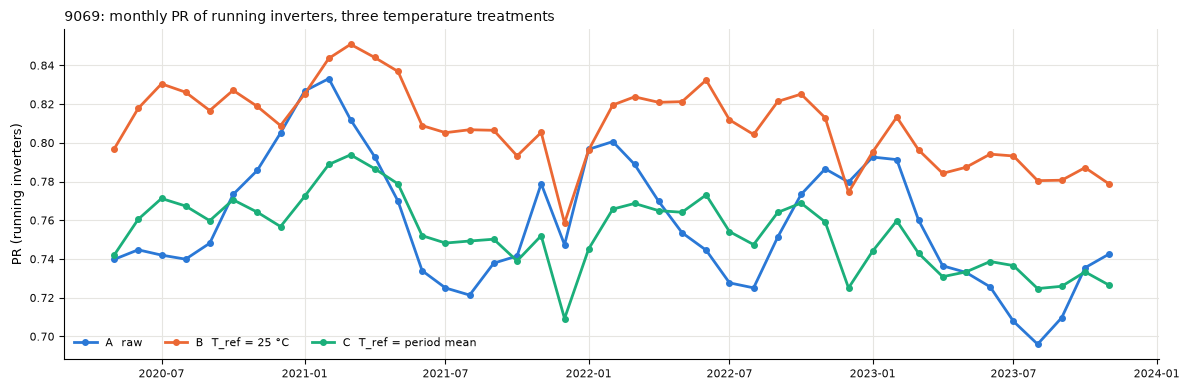

In [13]:
fig = plots.pr_variants_plot(monthly_kpi, title="9069: monthly PR of running inverters, three temperature treatments")
fig.savefig(FIG / "9069_pr_variants.png", dpi=130)

In [14]:
# Seasonal swing: spread of the monthly PR (excluding downtime), months with >= 90 % usable data.
full = monthly_kpi[monthly_kpi["pr_coverage"] >= 0.9]
summer, winter = full.index.month.isin([6, 7, 8]), full.index.month.isin([12, 1, 2])
cols = {"A raw": "pr_raw_excl_down", "B T_ref 25 C": "pr_stc_excl_down", "C T_ref period mean": "pr_wc_excl_down"}
swing = pd.DataFrame({
    name: {"mean": full[c].mean(), "std": full[c].std(), "max - min": full[c].max() - full[c].min(),
           "summer - winter": full.loc[summer, c].mean() - full.loc[winter, c].mean()}
    for name, c in cols.items()}).T
print(f"months used: {len(full)}")
swing.round(3)

months used: 40


,mean,std,max - min,summer - winter
A raw,0.760,0.034,0.137,-0.075
B T_ref 25 C,0.811,0.019,0.076,-0.000
C T_ref period mean,0.755,0.018,0.069,-0.005


In [15]:
# Sensitivity of PR (variant C, excluding downtime) to gamma.
gammas = {"nameplate -0.416": gamma, "measured (median within-month)": g.median() / 100,
          "datasheet 295 W -0.28": -0.0028}
sens = pd.DataFrame({name: kpi.kpi_table(inputs, ac, t_cell, config, gm, t_ref, freq="Y")["pr_wc_excl_down"]
                     for name, gm in gammas.items()})
sens.round(4)

,nameplate -0.416,measured (median within-month),datasheet 295 W -0.28
local_period,,,
2020,0.7615,0.7606,0.7596
2021,0.7623,0.7626,0.7629
2022,0.7606,0.7612,0.7619
2023,0.7346,0.7341,0.7336


## 7. KPIs: specific yield, availability, downtime map

Specific yield = measured AC energy / plant DC (kWh/kWp); missing data are not filled in, read it
with `yield_coverage`. 2020 (from May) and 2023 (to Nov) are partial years.
Availability is time-based; inverter-steps with unknown AC leave the denominator.

In [16]:
yearly_kpi[["e_ac_mwh", "h_poa_kwh_m2", "specific_yield_kwh_kwp", "yield_coverage", "availability",
            "pr_wc", "pr_wc_excl_down"]].round(3)

,e_ac_mwh,h_poa_kwh_m2,specific_yield_kwh_kwp,yield_coverage,availability,pr_wc,pr_wc_excl_down
local_period,,,,,,,
2020,34406.052,1227.488,892.109,0.996,0.957,0.733,0.762
2021,49057.120,1714.787,1276.180,0.999,0.966,0.737,0.762
2022,43112.042,1745.359,1120.444,0.999,0.830,0.636,0.761
2023,31193.209,1573.436,839.622,0.998,0.692,0.514,0.735


In [17]:
monthly_kpi[["specific_yield_kwh_kwp", "availability", "pr_wc", "pr_wc_excl_down", "pr_wc_meter"]].describe().round(3)

,specific_yield_kwh_kwp,availability,pr_wc,pr_wc_excl_down,pr_wc_meter
count,43.000,43.000,43.000,43.000,43.000
mean,96.008,0.853,0.647,0.754,0.654
std,26.808,0.145,0.117,0.019,0.094
min,36.598,0.548,0.413,0.709,0.416
25%,80.602,0.770,0.562,0.740,0.596
50%,94.629,0.896,0.666,0.754,0.656
75%,115.013,0.988,0.751,0.767,0.738
max,145.244,0.999,0.786,0.794,0.772


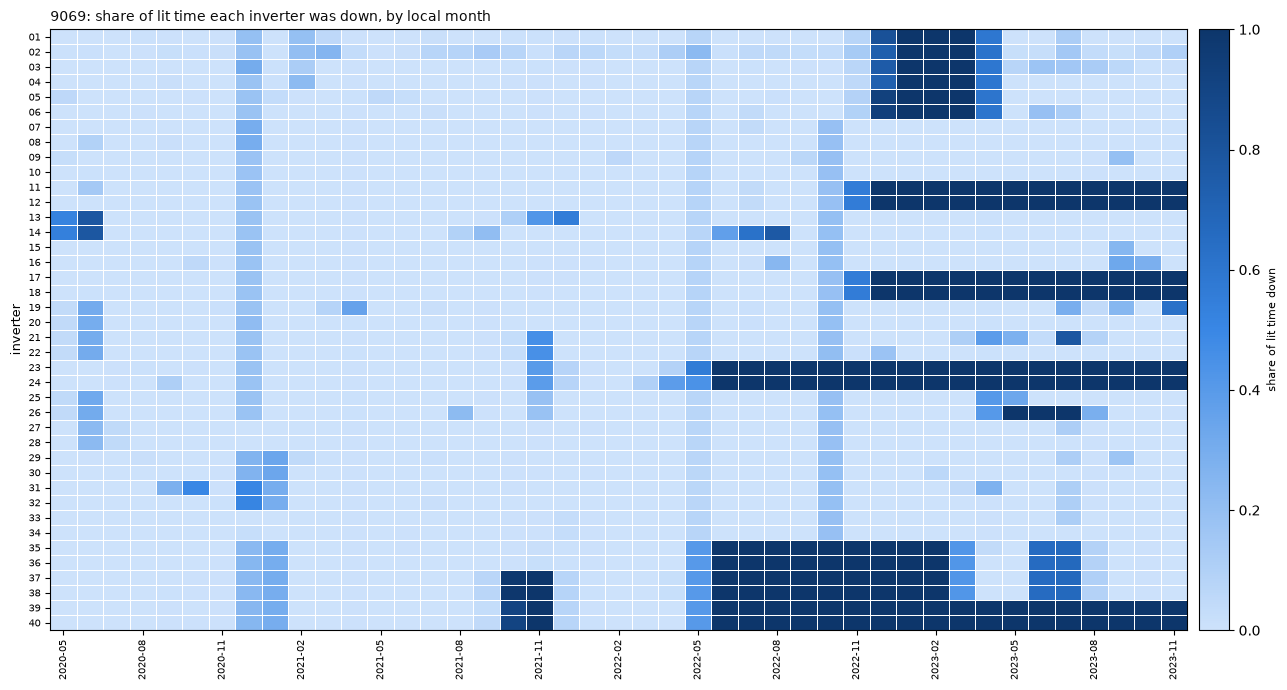

In [18]:
down = kpi.downtime_share(ac, inputs["poa_wm2"], config, freq="M")
down = down.loc[:, down.columns >= pd.Period("2020-05", "M")]   # drop the local stub month 2020-04
fig = plots.downtime_heatmap(down, title="9069: share of lit time each inverter was down, by local month")
fig.savefig(FIG / "9069_downtime_map.png", dpi=130)

In [19]:
# Inverters with the most downtime over the whole period (time-based).
known, is_down = kpi.inverter_states(ac, inputs["poa_wm2"], config)
per_inverter = (is_down.sum() / known.sum()).sort_values(ascending=False)
per_inverter.head(12).round(3)

p_ac_inv40_kw    0.480
p_ac_inv39_kw    0.479
p_ac_inv24_kw    0.455
p_ac_inv23_kw    0.445
p_ac_inv38_kw    0.318
p_ac_inv37_kw    0.318
p_ac_inv11_kw    0.294
p_ac_inv12_kw    0.290
p_ac_inv18_kw    0.290
p_ac_inv17_kw    0.290
p_ac_inv35_kw    0.273
p_ac_inv36_kw    0.273
dtype: float64

### Cross-check of downtime with the plant meter

An inverter channel at 0 kW can mean a stopped inverter or a lost data channel that reports 0.
The plant meter tells them apart: when inverters really stop, the meter drops with them and the
ratio sum of inverters / meter stays at its normal ≈ 1.02 (transformer and cable losses);
when a running inverter reports 0, the meter still counts its energy and the ratio falls below 1.

In [20]:
check = monthly_kpi[["inv_to_meter", "availability", "pr_wc", "pr_wc_meter"]]
print("whole period by year:")
print(yearly_kpi[["inv_to_meter", "availability", "pr_wc", "pr_wc_meter"]].round(3))
print()
print("months 2022-09 ... 2023-11:")
check.loc["2022-09":].round(3)

whole period by year:
              inv_to_meter  availability  pr_wc  pr_wc_meter
local_period                                                
2020                 1.021         0.957  0.733        0.717
2021                 1.015         0.966  0.737        0.727
2022                 1.023         0.830  0.636        0.622
2023                 0.886         0.692  0.514        0.581

months 2022-09 ... 2023-11:


,inv_to_meter,availability,pr_wc,pr_wc_meter
local_period,,,,
2022-09,1.029,0.797,0.611,0.593
2022-10,1.033,0.672,0.505,0.489
2022-11,1.031,0.730,0.557,0.541
2022-12,0.973,0.573,0.417,0.428
2023-01,0.994,0.549,0.413,0.416
2023-02,0.814,0.548,0.421,0.518
2023-03,0.758,0.604,0.454,0.600
2023-04,0.825,0.669,0.491,0.595
2023-05,0.916,0.757,0.556,0.607


## 8. Conclusions

**Inputs.** POA (cells 04 / 10) exists on 97.8 % and cell temperature on 97.7 % of daylight steps;
no value breaks the physical limits (POA ≤ 1260 W/m², T_cell ≤ 70 °C, AC ≤ 105 % of rating).

**Time offset (open question of Phase 1, closed).** Measured POA follows the sun (+2 min against
the clear-sky model, within the ±2.5 min precision). AC leads POA by about 7 min over the whole
day, but by 14 min in the morning and 0 min in the afternoon: a clock error would shift both
halves equally. After dividing AC by the temperature factor both halves are within ±2 min.
The apparent lead is the shape of the AC curve: modules heat up during the day, so AC per W/m²
is lower in the afternoon and the AC peak comes before the POA peak. The remaining whole-day
value (−4.7 min) comes from that morning/afternoon level difference, not from a time shift.
**No time correction is applied.** For 5-min residuals (Phase 5) this means: the temperature
model must be in the expectation, otherwise residuals have a daily morning/afternoon pattern.

**Temperature coefficient.** Measured per inverter (within-month fit): −0.34 ± 0.04 %/°C, all 40
between −0.24 and −0.38. No group of about 8 inverters at a clearly flatter slope, as −0.28
modules on their own inverters would produce. Inverters 29–40 are slightly flatter than 01–28
(−0.30 vs −0.35): a weak hint, not proof of where the 295 W modules are. The measured slope is
probably flatter than the true one: three thermocouples stand for 40 blocks, and noise in the
explanatory variable flattens a regression slope (regression dilution). **The model keeps the
DC-weighted nameplate −0.416 %/°C.** Annual PR of variant C hardly depends on gamma (≤ 0.002
between −0.28 and −0.416), because T_ref is the mean operating temperature; gamma matters for
the temperature loss step of the waterfall (Phase 3).

**Cell drift.** Cells 04 / 10 against pyranometer 02B, year-over-year 2020-07 … 2022-04:
−0.6 / −1.0 %/yr (10 pairs, ranges −1.5 … +1.1 and −2.3 … +0.3). The medians are above the 0.5 %/yr
threshold, but 10 pairs cannot separate them from zero, and the data cannot tell which device
drifts (an unrecalibrated thermopile pyranometer also drifts by up to about 1 %/yr). The figure
shows a step of about −1.5 % for both cells around 2021-02 and flat ratios before and after,
which looks like an event (cleaning, recalibration or replacement of one device) rather than
gradual ageing; a year-over-year median turns such a step into a "drift". Cell 04
against cell 10 is stable (−0.1 %/yr over the whole period). **No correction is applied**; the
possible cell drift is carried as an uncertainty of about ±1 %/yr. A cell that reads lower
every year makes PR look higher every year, so it matters for the degradation rate in Phase 4.

**Expected yield.** Running inverters produce 0.935 (2020), 0.918 (2021), 0.919 (2022) and 0.886
(2023) of the nameplate model at 400–900 W/m². The 6–11 % gap (soiling, degradation, sensor
offset, the assumed design losses and inverter efficiency) is what Phases 3–4 must break down;
the 2023 step down is real, not a sensor effect (cell 04 / cell 10 is stable).

**PR variants.** T_ref of variant C = 41.5 °C. On 40 months with ≥ 90 % usable data:
A (raw) swings by 0.137 between months and is 0.075 lower in summer than in winter; B and C
remove the seasonal swing (std 0.019 / 0.018, summer − winter ≈ 0). B is 0.056 higher than C,
as expected from |gamma| × (41.5 − 25 °C) ≈ 7 % relative. PR of running inverters (C) is
0.762 / 0.762 / 0.761 in 2020–2022 and 0.735 in 2023. **Use:** C for trends and the loss
waterfall, B for comparison with contract or STC-based values, A only to show the weather effect.
C still dips in November–December (0.71–0.73): low sun (row shading, angle of incidence) is a
candidate, to be checked in Phase 3.

**Availability and the meter cross-check.** Time-based availability: 0.957 (2020), 0.966 (2021),
0.830 (2022), 0.692 (2023). Inverters fail in pairs (39 + 40, 23 + 24, 37 + 38, 11 + 12, 17 + 18,
35 + 36), which points at shared equipment. The downtime map also shows plant-wide events
(all inverters partly down in 2020-12 / 2021-01, 2022-05 and 2022-10): grid or plant-level
causes, which a contract may treat differently from inverter faults. Until 2022-11 the meter confirms the outages
(inverters / meter stays at 1.00–1.03 even with 7–11 inverters at 0). In 2022-12 and 2023-01 it
slips to 0.97–0.99, and **from 2023-02 it falls to 0.76–0.95** (0.886 for 2023): the meter
counts energy that inverter channels at 0 do not report, so part
of the 2023 "downtime" is lost data, not stopped inverters. Inverter-based availability and PR
including downtime are therefore understated in 2023; the meter PR (C) of 2023 is 0.581
against 0.514 from the inverter channels.

**For Phase 3.** (1) How to separate real downtime from data loss per inverter using the meter:
a methodological choice, options to be discussed before coding. (2) Why inverters fail in pairs,
and which outages are plant-wide. (3) What causes the 2023 drop of running inverters (≈ 3 %).
(4) The November–December dip of PR (C).

## Revision after Phase 3: availability and PR with lost data channels (added in Phase 5)

The Phase 2 tables above are **kept unchanged**. The waterfall of Phase 3 showed that part of the zeros reported by the
inverters (above all from 2022-12 to 2023-11) are lost data channels, not stops: the meter sees energy that the inverter channels do not
report. Which inverter lies cannot be read from the files, so the correction works at plant level.

Three availability numbers per period (`src/losses.py::availability_revised`):
- **raw** (lower bound): every zero is a real stop, as in Phase 2;
- **upper bound**: apparent stops on channel-loss days leave the denominator (real stops of those days are dropped too);
- **energy** (central): 1 - (downtime + channel credit) / expected energy of the waterfall = the stop energy that the meter confirms.

PR with downtime: the **meter PR** is not affected by channel loss and is the headline; the inverter PR with downtime is a cross-check.

In [1]:
import os, sys, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import load_config
from src.model import load_inputs, cell_temperature, weighted_gamma
from src.kpi import kpi_table, weighted_t_ref
from src.losses import availability_revised

cfg = load_config("configs/system_9069.yaml")
inputs, ac = load_inputs(cfg)
t_cell = cell_temperature(inputs, cfg)
gamma = weighted_gamma(cfg)
base = inputs["daylight"] & inputs["poa_wm2"].notna() & t_cell.notna()
t_ref = weighted_t_ref(t_cell, inputs["poa_wm2"], base)

av = availability_revised(inputs, ac, t_cell, cfg, gamma, freq="Y")
kp = kpi_table(inputs, ac, t_cell, cfg, gamma, t_ref, freq="Y")
table = pd.concat([av, kp[["pr_wc", "pr_wc_excl_down", "pr_wc_meter", "inv_to_meter"]]], axis=1)
table.index = table.index.astype(str)
print("Availability and PR (C) per year; channel_days = local days with sum(inverters) / meter < 0.97:")
print(table.round(3).T.to_string())

Availability and PR (C) per year; channel_days = local days with sum(inverters) / meter < 0.97:
local_period               2020    2021    2022     2023
availability_time_raw     0.957   0.966   0.830    0.692
availability_time_upper   0.977   0.978   0.845    0.939
availability_energy       0.967   0.971   0.838    0.791
channel_days             28.000  40.000  12.000  281.000
pr_wc                     0.733   0.737   0.636    0.514
pr_wc_excl_down           0.762   0.762   0.761    0.735
pr_wc_meter               0.717   0.727   0.622    0.581
inv_to_meter              1.021   1.015   1.023    0.886


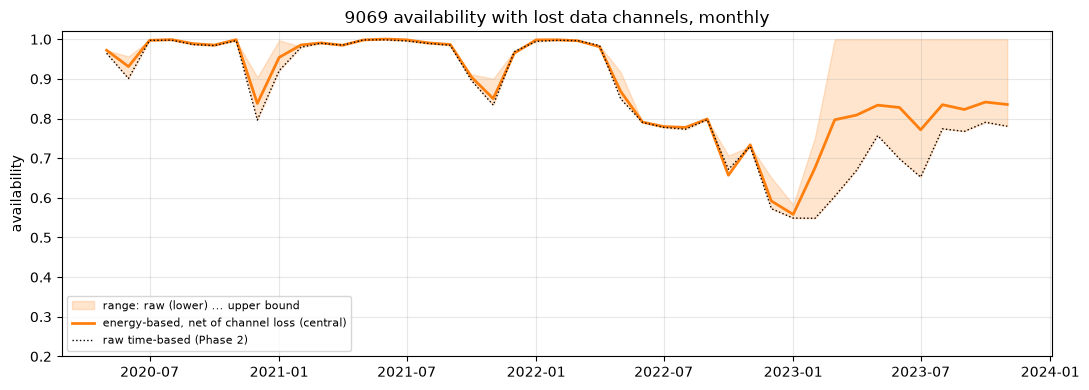

months where the range (upper - raw) exceeds 10 pp: 11 of 43


In [2]:
av_m = availability_revised(inputs, ac, t_cell, cfg, gamma, freq="M")
x = av_m.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, av_m.availability_time_raw, av_m.availability_time_upper, color="C1", alpha=.2,
                label="range: raw (lower) ... upper bound")
ax.plot(x, av_m.availability_energy, "C1", lw=2, label="energy-based, net of channel loss (central)")
ax.plot(x, av_m.availability_time_raw, "k:", lw=1, label="raw time-based (Phase 2)")
ax.set(ylabel="availability", ylim=(0.2, 1.02), title="9069 availability with lost data channels, monthly")
ax.legend(fontsize=8, loc="lower left"); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig("reports/figures/9069_availability_revised.png", dpi=130); plt.show()
print("months where the range (upper - raw) exceeds 10 pp:", int(((av_m.availability_time_upper - av_m.availability_time_raw) > 0.10).sum()), "of", len(av_m))

### Conclusions of the revision
- **2020-2022: the correction is small.** Availability (raw / central / upper) is 0.957 / 0.967 / 0.977 in 2020, 0.966 / 0.971 / 0.978 in 2021 and 0.830 / 0.838 / 0.845 in 2022; there are 28, 40 and 12 channel-loss days. The Phase 2 numbers for these years stand.
- **2023: the Phase 2 availability of 0.692 is a lower bound, not the plant's availability.** Raw 0.692, central (energy, net of channel loss) **0.791**, upper bound 0.939; 281 channel-loss days. From 2023-03 to 2023-11 *every* day is a channel-loss day (sum of inverters / meter below 0.97), so the upper bound is 1.00 in those months and says nothing; the central estimate rests on the energy the meter confirms. In the months of 2023-03 ... 11 it lies between 0.77 and 0.84, raw between 0.60 and 0.79. Quote 2023 as **0.79 (energy-based; time-based raw 0.69 is a lower bound)**, never as 0.69.
- **PR with downtime.** The inverter-based PR (C) incl. downtime is 0.514 in 2023, the meter-based PR (C) 0.581: the inverter value is understated by about 7 pp because lost channels count as zero energy. The sum of inverters / meter is 0.886 in 2023 (1.015-1.023 in 2020-2022). Use the **meter PR (0.717 / 0.727 / 0.622 / 0.581 for 2020-2023)** as the headline PR with downtime. The PR of the running inverters (0.762 / 0.762 / 0.761 / 0.735) is not affected by lost channels.
- **Limits.** Which inverters report false zeros cannot be read from these files, so nothing here is an availability per inverter. The energy-based number is energy-weighted (the sunny hours count more) and has a small bias towards lower availability: the credit is the energy at the *measured* level of the missing channels, so their running shortfall (about 10 % of expected energy, Phase 3) stays in the stop energy. The range raw ... upper exceeds 10 percentage points in 11 of 43 months.
- **Open (see notebook 05):** the groups of inverters that stop together (11 + 12 + 17 + 18, 23 + 24, 35 + 36, 37 + 38, 39 + 40) are the likely carriers of the 2023 zeros, but whether they are real stops or lost channels is not decidable from the inverter channels alone.
